# Phase 1: Simulating Quantum Noise (Before Error Correction)

## What this notebook does:
We take a qubit, hit it with different types of noise, and measure how badly the noise damages it.

## Why we do this:
This gives us the **baseline** — how bad things are WITHOUT any error correction.
Later (Phase 2), we'll add error correction codes and compare: did the code actually help?

## What we measure:
- **Fidelity** = how similar is the noisy qubit to the original? (1.0 = perfect, 0.0 = completely destroyed)
- **Physical error rate** = what fraction of measurements gave the wrong answer?

---
## Step 1: Import Libraries
These are the tools we need. Think of them as apps on your phone — each one does a specific job.

In [1]:
# === MATH & DATA TOOLS ===
import numpy as np                # For math operations (arrays, random numbers)
import pandas as pd               # For organizing results into tables
import matplotlib.pyplot as plt   # For plotting graphs

# === QISKIT CORE ===
from qiskit import QuantumCircuit                        # To build quantum circuits
from qiskit.quantum_info import Statevector, state_fidelity  # To get qubit states and compare them
from qiskit.visualization import plot_histogram           # To draw bar charts of measurement results

# === QISKIT SIMULATOR & NOISE ===
from qiskit_aer import AerSimulator                      # The virtual quantum computer
from qiskit_aer.noise import (
    NoiseModel,               # Container that holds noise settings
    pauli_error,              # To create bit-flip noise
    depolarizing_error,       # To create depolarizing noise
    amplitude_damping_error,  # To create amplitude damping noise
)

# Make graphs look nice
plt.rcParams['figure.dpi'] = 110

# Fix random seed so results are reproducible (same random numbers every time)
np.random.seed(42)

print('All libraries loaded successfully!')

All libraries loaded successfully!


---
## Step 2: Prepare Test Qubits

We need some known qubit states to test our noise on. We pick 3:

| State | What it is | How to make it |
|-------|-----------|----------------|
| \|0⟩ | Qubit pointing "up" (default state) | Do nothing |
| \|1⟩ | Qubit pointing "down" | Apply X gate (flips 0→1) |
| \|+⟩ | Qubit in superposition (both 0 and 1) | Apply H gate (Hadamard) |

**Why these 3?** Because different noise types affect different states differently.
For example, bit-flip noise won't affect \|+⟩ at all (we'll see this later).

In [2]:
def make_qubit(state_name):
    """
    Create a 1-qubit circuit that prepares the given state.
    
    state_name can be:
      '0' → |0⟩ (do nothing, qubit starts as 0 by default)
      '1' → |1⟩ (apply X gate to flip 0 to 1)
      '+' → |+⟩ (apply H gate to create superposition)
    """
    circuit = QuantumCircuit(1)   # Create a circuit with 1 qubit
    
    if state_name == '1':
        circuit.x(0)             # X gate: flips |0⟩ to |1⟩
    elif state_name == '+':
        circuit.h(0)             # H gate: puts qubit in superposition
    # If state_name == '0', we do nothing (qubit is already |0⟩)
    
    return circuit


# Test it: print what each state looks like mathematically
for name in ['0', '1', '+']:
    state_vector = Statevector(make_qubit(name))   # Get the math representation
    print(f'|{name}⟩  →  {state_vector.data.round(3)}')
    
# Expected output:
# |0⟩ → [1, 0]       means: 100% chance of measuring 0
# |1⟩ → [0, 1]       means: 100% chance of measuring 1  
# |+⟩ → [0.707, 0.707]  means: 50% chance of 0, 50% chance of 1

|0⟩  →  [1.+0.j 0.+0.j]
|1⟩  →  [0.+0.j 1.+0.j]
|+⟩  →  [0.707+0.j 0.707+0.j]


---
## Step 3: Create Noise Models

Now we build the 3 types of noise our project tests:

### Noise Type 1: Bit-Flip
- With probability `p`, the qubit flips: 0→1 or 1→0
- Like someone randomly flipping your light switch

### Noise Type 2: Depolarizing  
- With probability `p`, a random error hits (could be X, Y, or Z)
- Like the qubit getting scrambled in a random direction

### Noise Type 3: Amplitude Damping
- The qubit loses energy: |1⟩ decays toward |0⟩
- Like a ball rolling downhill — only goes one way

**Important:** We attach noise to the `id` (identity/idle) gate. This gate does nothing by itself — it just represents the qubit sitting there doing nothing while noise hits it.

In [3]:
def make_bit_flip_noise(p):
    """
    Bit-Flip noise: with probability p, apply X gate (flip the qubit).
    With probability (1-p), apply I gate (do nothing).
    """
    error = pauli_error([
        ('X', p),       # p chance of flipping
        ('I', 1 - p)    # (1-p) chance of doing nothing
    ])
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(error, ['id'])  # Attach to idle gate
    return noise_model


def make_depolarizing_noise(p):
    """
    Depolarizing noise: with probability p, apply a RANDOM error (X, Y, or Z).
    Each of X, Y, Z has equal chance (p/3 each).
    """
    error = depolarizing_error(p, 1)   # p = total error probability, 1 = single qubit
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(error, ['id'])
    return noise_model


def make_amplitude_damping_noise(gamma):
    """
    Amplitude Damping: qubit in |1⟩ decays to |0⟩ with probability gamma.
    Qubit in |0⟩ is unaffected (it's already at the lowest energy).
    """
    error = amplitude_damping_error(gamma)   # gamma = decay probability
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(error, ['id'])
    return noise_model


# Store all 3 noise makers in a dictionary for easy looping later
noise_makers = {
    'Bit-Flip':          make_bit_flip_noise,
    'Depolarizing':      make_depolarizing_noise,
    'Amplitude Damping': make_amplitude_damping_noise,
}

print('All 3 noise models ready!')

All 3 noise models ready!


---
## Step 4: Sanity Check — See Noise in Action

Before doing the full experiment, let's do ONE simple test to see if noise actually works:

1. Prepare |0⟩
2. Apply 30% bit-flip noise (so there's a 30% chance it flips to |1⟩)
3. Measure 2000 times
4. Compare with the noiseless case

**Expected:** Without noise, we should get 0 every time. With 30% noise, we should get 1 about 30% of the time.

Without noise: {'0': 2000}
With 30% noise: {'1': 574, '0': 1426}


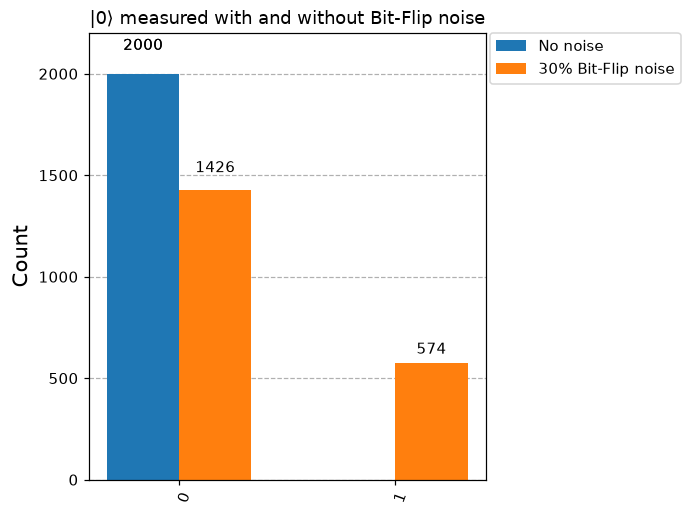

In [4]:
# Build the circuit: prepare |0⟩, add idle gate (where noise will attach), measure
demo_circuit = make_qubit('0')     # Start with |0⟩
demo_circuit.id(0)                 # Idle gate — noise attaches here
demo_circuit.measure_all()         # Measure the qubit

# Run WITHOUT noise (perfect simulator)
perfect_sim = AerSimulator()
perfect_results = perfect_sim.run(demo_circuit, shots=2000).result().get_counts()

# Run WITH 30% bit-flip noise
noisy_sim = AerSimulator(noise_model=make_bit_flip_noise(0.30))
noisy_results = noisy_sim.run(demo_circuit, shots=2000).result().get_counts()

# Print raw numbers
print(f'Without noise: {perfect_results}')   # Should be all 0s
print(f'With 30% noise: {noisy_results}')     # Should be ~70% 0s, ~30% 1s

# Plot side by side
plot_histogram(
    [perfect_results, noisy_results],
    legend=['No noise', '30% Bit-Flip noise'],
    title='|0⟩ measured with and without Bit-Flip noise',
)

---
## Step 5: The Main Experiment — Fidelity vs Noise

Now the real experiment. For EVERY combination of:
- 3 noise types (Bit-Flip, Depolarizing, Amplitude Damping)
- 3 qubit states (|0⟩, |1⟩, |+⟩)
- 10 noise levels (0% to 50%)

That's 3 × 3 × 10 = **90 experiments**.

For each one, we:
1. Prepare the qubit in the test state
2. Apply noise at the given probability
3. Get the resulting noisy state (as a density matrix — a way to represent mixed/noisy states)
4. Compare it to the ideal state using **fidelity**

**Note:** We use `save_density_matrix()` instead of `measure_all()` here. Why?
Because measurement collapses the qubit to 0 or 1 — we'd lose the quantum information.
Density matrix lets us see the FULL noisy state without collapsing it.

In [5]:
# Noise levels to test: from 0% (no noise) to 50% (extreme noise)
noise_levels = [0.0, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]

# The 3 test states
test_states = ['0', '1', '+']


def measure_fidelity(state_name, noise_type, noise_prob):
    """
    Prepare a qubit, hit it with noise, and measure how damaged it is.
    
    Returns: fidelity (float between 0 and 1)
      1.0 = qubit is perfectly intact
      0.0 = qubit is completely destroyed
    """
    # STEP A: Build the circuit
    circuit = make_qubit(state_name)     # Prepare the qubit
    circuit.id(0)                        # Add idle gate (noise attaches here)
    circuit.save_density_matrix()        # Save the full quantum state (don't collapse it)
    
    # STEP B: Create the noisy simulator
    noise_model = noise_makers[noise_type](noise_prob)   # Build noise with given probability
    simulator = AerSimulator(method='density_matrix', noise_model=noise_model)
    
    # STEP C: Run the simulation
    result = simulator.run(circuit).result()
    noisy_state = result.data(0)['density_matrix']   # Extract the noisy density matrix
    
    # STEP D: Compare noisy state with the ideal (noiseless) state
    ideal_state = Statevector(make_qubit(state_name))  # What the state SHOULD be
    fidelity = state_fidelity(ideal_state, noisy_state) # How close are they? (0 to 1)
    
    return fidelity


# === RUN ALL 90 EXPERIMENTS ===
all_results = []   # We'll store every result here

for noise_type in noise_makers:          # Loop over 3 noise types
    for state_name in test_states:        # Loop over 3 states
        for p in noise_levels:             # Loop over 10 noise levels
            fid = measure_fidelity(state_name, noise_type, p)
            all_results.append({
                'noise_type': noise_type,
                'state': f'|{state_name}⟩',
                'noise_prob': p,
                'fidelity': round(fid, 4)
            })

# Convert to a nice table
results_table = pd.DataFrame(all_results)

# Show first 10 rows
print(f'Total experiments: {len(results_table)}')
results_table.head(10)

Total experiments: 90


,noise_type,state,noise_prob,fidelity
0,Bit-Flip,|0⟩,0.00,1.00
1,Bit-Flip,|0⟩,0.01,0.99
2,Bit-Flip,|0⟩,0.02,0.98
3,Bit-Flip,|0⟩,0.05,0.95
4,Bit-Flip,|0⟩,0.10,0.90
5,Bit-Flip,|0⟩,0.15,0.85
6,Bit-Flip,|0⟩,0.20,0.80
7,Bit-Flip,|0⟩,0.30,0.70
8,Bit-Flip,|0⟩,0.40,0.60
9,Bit-Flip,|0⟩,0.50,0.50


### Plot the Results

Three graphs side by side — one per noise type. Each graph shows how fidelity drops as noise increases, for all 3 test states.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, noise_type in zip(axes, noise_makers):
    # Filter data for this noise type
    subset = results_table[results_table.noise_type == noise_type]
    
    # Plot each state as a separate line
    for state_name, group in subset.groupby('state'):
        ax.plot(group.noise_prob, group.fidelity, marker='o', label=state_name)
    
    ax.set_title(noise_type)
    ax.set_xlabel('Noise Probability')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Fidelity')
axes[0].legend(title='State')
fig.suptitle('How Noise Damages Qubits (Before Any Error Correction)', fontsize=13)
fig.tight_layout()

import os
os.makedirs('outputs/Phase1_Noise_Simulation', exist_ok=True)
fig.savefig('outputs/Phase1_Noise_Simulation/fidelity_vs_noise_probability.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nKey observations:')
print('• Bit-Flip: |+⟩ stays at 1.0 — bit-flip noise cant hurt a superposition state!')
print('• Amplitude Damping: |0⟩ stays at 1.0 — already at lowest energy, cant decay further')
print('• Depolarizing: ALL states get damaged — its the most destructive noise')

---
## Step 6: Verify Our Noise is Correct

A sanity check: if we inject 5% bit-flip noise, do we actually see ~5% of measurements flip?

We prepare |0⟩, apply bit-flip noise at each probability, measure 5000 times, and count how many times we got |1⟩ (which means a flip happened). The measured flip rate should match the injected probability.

In [ ]:
num_shots = 5000    # Measure each experiment 5000 times for statistical accuracy
validation_results = []

for p in noise_levels:
    # Build circuit: prepare |0⟩ → idle gate → measure
    circuit = make_qubit('0')
    circuit.id(0)
    circuit.measure_all()
    
    # Run with bit-flip noise at probability p
    sim = AerSimulator(noise_model=make_bit_flip_noise(p))
    counts = sim.run(circuit, shots=num_shots).result().get_counts()
    
    # Count how many times we got '1' (meaning a flip happened)
    # counts.get('1', 0) means: get the count for '1', or 0 if no flips happened
    flips = counts.get('1', 0)
    measured_error_rate = flips / num_shots
    
    validation_results.append({
        'injected_probability': p,
        'measured_error_rate': measured_error_rate
    })

validation_table = pd.DataFrame(validation_results)

# Plot: if noise is working correctly, the dots should fall on the diagonal line
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(validation_table.injected_probability, validation_table.injected_probability,
        '--', color='gray', label='Theoretical (perfect match)')
ax.plot(validation_table.injected_probability, validation_table.measured_error_rate,
        'o-', color='crimson', label='Simulated (what we measured)')
ax.set_xlabel('Injected Bit-Flip Probability')
ax.set_ylabel('Measured Error Rate')
ax.set_title('Noise Validation: Does Our Simulator Inject Noise Correctly?')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

import os
os.makedirs('outputs/Phase1_Noise_Simulation', exist_ok=True)
fig.savefig('outputs/Phase1_Noise_Simulation/physical_error_rate_validation.png', dpi=150, bbox_inches='tight')
plt.show()

print('If the red dots sit on the gray dashed line, our noise is working correctly!')
print()
validation_table

---
## Step 7: Save Results

Save everything to CSV files so we can use these baselines in Phase 2.

In [ ]:
import os
os.makedirs('outputs/Phase1_Noise_Simulation', exist_ok=True)
results_table.to_csv('outputs/Phase1_Noise_Simulation/noise_fidelity_results.csv', index=False)
validation_table.to_csv('outputs/Phase1_Noise_Simulation/physical_error_rate_results.csv', index=False)

print('Saved: outputs/Phase1_Noise_Simulation/noise_fidelity_results.csv')
print('Saved: outputs/Phase1_Noise_Simulation/physical_error_rate_results.csv')
print()
print('Phase 1 complete!')
print('Next: Phase 2 — add error correction codes and compare.')

---
## Summary: What We Learned

1. **Fidelity drops as noise increases** — all noise types damage qubits, but in different ways
2. **Bit-Flip noise** can't hurt |+⟩ (superposition state) — that's a blind spot only the Phase-Flip code can fix
3. **Amplitude Damping** can't hurt |0⟩ (lowest energy state) — but it destroys |1⟩ steadily
4. **Depolarizing noise** damages everything equally — it's the most general and destructive
5. Our noise injection is **calibrated correctly** — measured error rates match injected probabilities

## What's Next (Phase 2):
1. Build the 3-qubit Bit-Flip correction code
2. Build the 3-qubit Phase-Flip correction code
3. Build the 9-qubit Shor code (corrects both)
4. Run the same noise sweep WITH correction
5. Compare logical error rate vs physical error rate
6. Find the pseudo-threshold (breakeven point)